# DS605 — PCA, Eigenfaces and Face Recognition

AT&T / ORL face database


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

np.random.seed(42)
DATA_PATH = Path(r"C:\Users\DELL\Downloads\archive (1)")
OUTPUT_PATH = Path("outputs")
OUTPUT_PATH.mkdir(exist_ok=True)


In [2]:
def find_dataset_root(path):
    path = Path(path)
    candidates = [path] + [p for p in path.rglob("*") if p.is_dir()]
    for folder in candidates:
        subjects = [p for p in folder.iterdir()
                    if p.is_dir() and p.name.lower().startswith("s")
                    and p.name[1:].isdigit()]
        if subjects:
            return folder
    raise FileNotFoundError("Could not locate subject folders such as s1, s2, ...")

root = find_dataset_root(DATA_PATH)
subject_dirs = sorted(
    [p for p in root.iterdir() if p.is_dir() and p.name.lower().startswith("s")
     and p.name[1:].isdigit()],
    key=lambda p: int(p.name[1:])
)

images, labels, image_paths = [], [], []
for folder in subject_dirs:
    for file in sorted(folder.iterdir()):
        if file.suffix.lower() not in {".pgm", ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}:
            continue
        with Image.open(file) as im:
            image = np.asarray(im.convert("L"), dtype=np.float64)
        images.append(image)
        labels.append(int(folder.name[1:]))
        image_paths.append(str(file))

images = np.stack(images)
y = np.asarray(labels)
X = images.reshape(len(images), -1)
n_images, height, width = images.shape

print(f"Dataset: {root}")
print(f"Images: {n_images} | Subjects: {len(np.unique(y))}")
print(f"Image size: {height} x {width} | Feature matrix: {X.shape}")
print(f"Pixel intensity range: {images.min():.0f}–{images.max():.0f}")


Dataset: C:\Users\DELL\Downloads\archive (1)
Images: 400 | Subjects: 40
Image size: 112 x 92 | Feature matrix: (400, 10304)
Pixel intensity range: 0–251


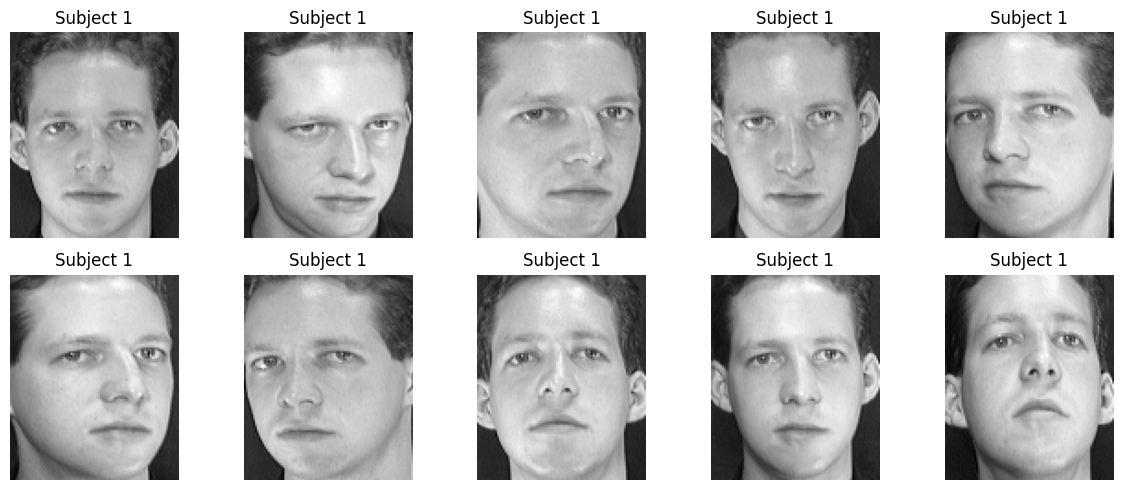

Training images: 280 | Test images: 120
Subjects represented in train/test: 40/40


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Subject {y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, y, np.arange(len(y)), test_size=0.30, random_state=42, stratify=y
)
print(f"Training images: {len(X_train)} | Test images: {len(X_test)}")
print(f"Subjects represented in train/test: {len(np.unique(y_train))}/{len(np.unique(y_test))}")


In [4]:
mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face

# Covariance/eigendecomposition in sample space
gram = X_train_centered @ X_train_centered.T
eigvals, eigvecs = np.linalg.eigh(gram)
order = np.argsort(eigvals)[::-1]
eigvals = np.maximum(eigvals[order], 0)
eigvecs = eigvecs[:, order]
valid = eigvals > max(eigvals[0] * 1e-12, 1e-12)
eigvals, eigvecs = eigvals[valid], eigvecs[:, valid]
components_eig = (X_train_centered.T @ eigvecs) / np.sqrt(eigvals)[None, :]
components_eig /= np.linalg.norm(components_eig, axis=0, keepdims=True) + 1e-15

# Independent PCA computation using SVD
U, singular_values, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
components_svd = Vt.T
svd_eigenvalues = singular_values ** 2

explained_variance = eigvals / eigvals.sum()
cumulative_variance = np.cumsum(explained_variance)
k90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)
k90 = min(k90, len(cumulative_variance))

compare_k = min(20, components_eig.shape[1], components_svd.shape[1])
direction_agreement = np.abs(
    np.sum(components_eig[:, :compare_k] * components_svd[:, :compare_k], axis=0)
)

print(f"Components for at least 90% variance: {k90}")
print(f"Variance retained: {cumulative_variance[k90-1]*100:.2f}%")
print(f"Mean absolute direction agreement between eigendecomposition and SVD: {direction_agreement.mean():.6f}")


Components for at least 90% variance: 91
Variance retained: 90.05%
Mean absolute direction agreement between eigendecomposition and SVD: 1.000000


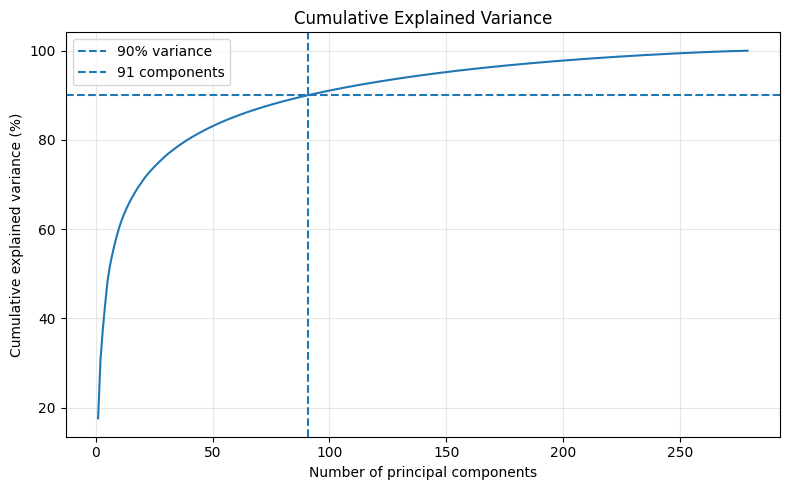

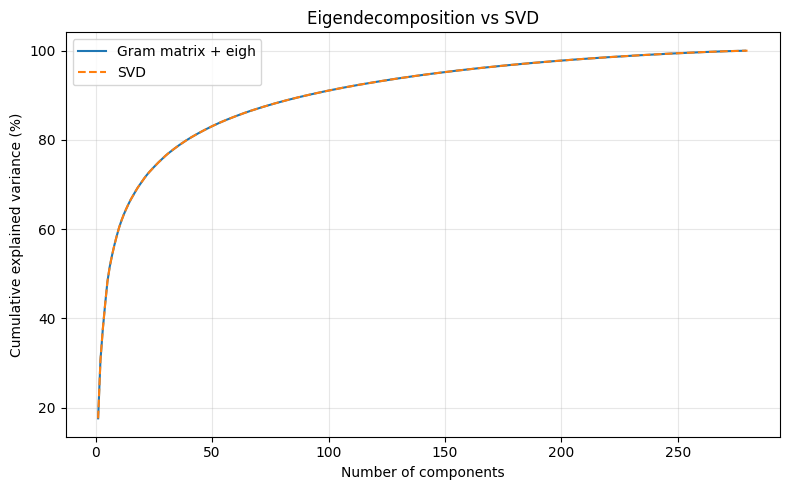

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance * 100)
plt.axhline(90, linestyle="--", label="90% variance")
plt.axvline(k90, linestyle="--", label=f"{k90} components")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("Cumulative Explained Variance")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "explained_variance.png", dpi=160)
plt.show()

svd_variance = svd_eigenvalues / svd_eigenvalues.sum()
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(explained_variance)+1),
         np.cumsum(explained_variance)*100, label="Gram matrix + eigh")
plt.plot(np.arange(1, len(svd_variance)+1),
         np.cumsum(svd_variance)*100, "--", label="SVD")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("Eigendecomposition vs SVD")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "eigendecomposition_vs_svd.png", dpi=160)
plt.show()


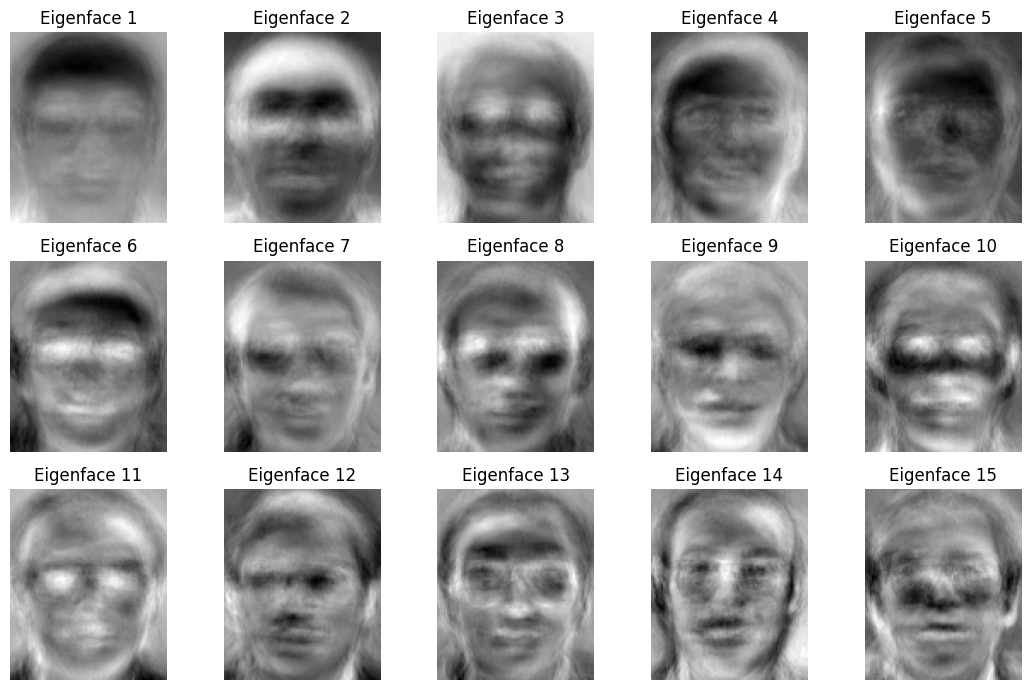

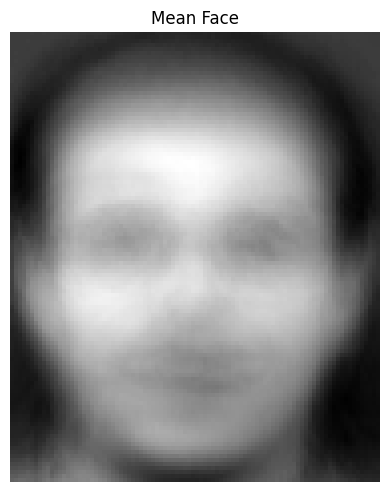

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for i, ax in enumerate(axes.flat):
    face = components_eig[:, i].reshape(height, width)
    lo, hi = face.min(), face.max()
    ax.imshow((face - lo) / (hi - lo + 1e-12), cmap="gray")
    ax.set_title(f"Eigenface {i+1}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "eigenfaces.png", dpi=160)
plt.show()

plt.figure(figsize=(4, 5))
plt.imshow(mean_face.reshape(height, width), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "mean_face.png", dpi=160)
plt.show()


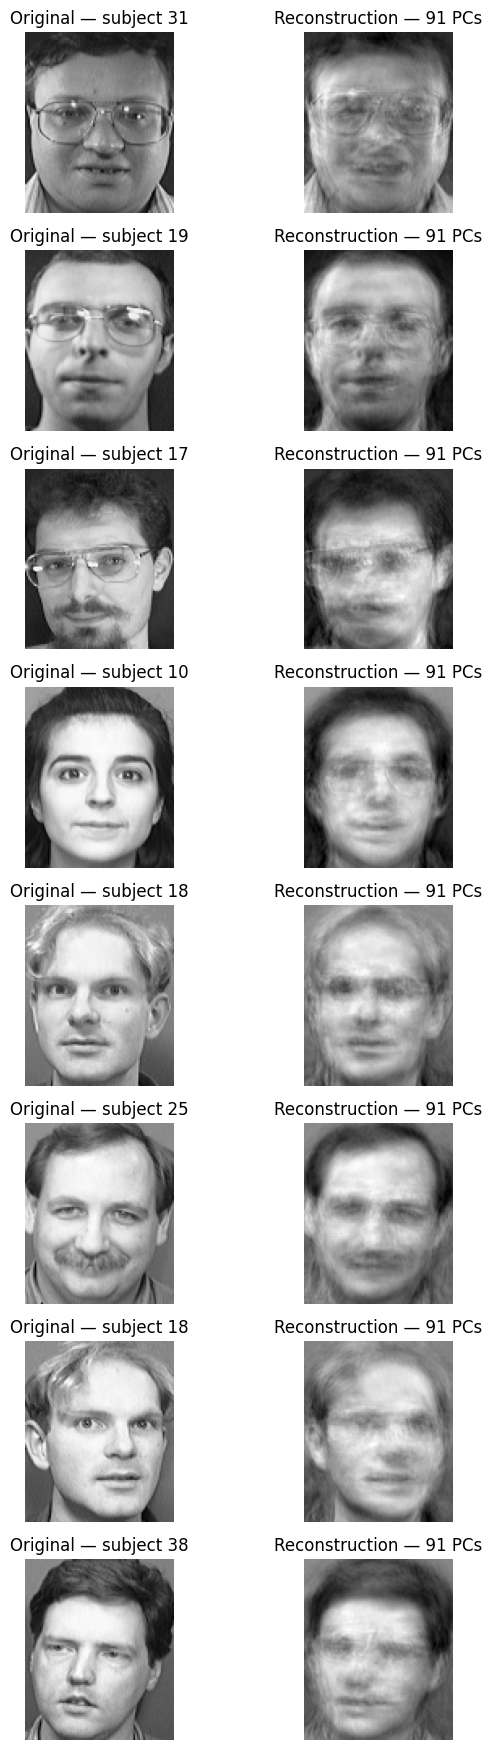

Reconstruction MSE: 343.044
Training pixel matrix storage: 23,080,960 bytes
PCA codes + basis + mean storage: 7,787,584 bytes
Approximate storage ratio: 2.96x


In [7]:
components = components_eig[:, :k90]

def project(data, basis=components):
    return (data - mean_face) @ basis

Z_train = project(X_train)
Z_test = project(X_test)

np.savez_compressed(
    OUTPUT_PATH / "pca_representations.npz",
    Z_train=Z_train, Z_test=Z_test, y_train=y_train, y_test=y_test,
    components=components, mean_face=mean_face,
    train_indices=train_idx, test_indices=test_idx
)

sample_count = min(8, len(X_test))
Z_sample = Z_test[:sample_count]
reconstructed = Z_sample @ components.T + mean_face
reconstructed_images = np.clip(reconstructed.reshape(-1, height, width), 0, 255)

fig, axes = plt.subplots(sample_count, 2, figsize=(7, 2.2 * sample_count), squeeze=False)
for i in range(sample_count):
    axes[i, 0].imshow(X_test[i].reshape(height, width), cmap="gray")
    axes[i, 0].set_title(f"Original — subject {y_test[i]}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(reconstructed_images[i], cmap="gray")
    axes[i, 1].set_title(f"Reconstruction — {k90} PCs")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "reconstruction_examples.png", dpi=160)
plt.show()

reconstruction_mse = np.mean((X_test[:sample_count] - reconstructed) ** 2)
original_bytes = X_train.size * X_train.dtype.itemsize
pca_bytes = (Z_train.size * Z_train.dtype.itemsize +
             components.size * components.dtype.itemsize +
             mean_face.size * mean_face.dtype.itemsize)
print(f"Reconstruction MSE: {reconstruction_mse:.3f}")
print(f"Training pixel matrix storage: {original_bytes:,} bytes")
print(f"PCA codes + basis + mean storage: {pca_bytes:,} bytes")
print(f"Approximate storage ratio: {original_bytes / pca_bytes:.2f}x")


Raw-pixel nearest-neighbor accuracy: 0.9667
PCA nearest-neighbor accuracy (91 components): 0.9667


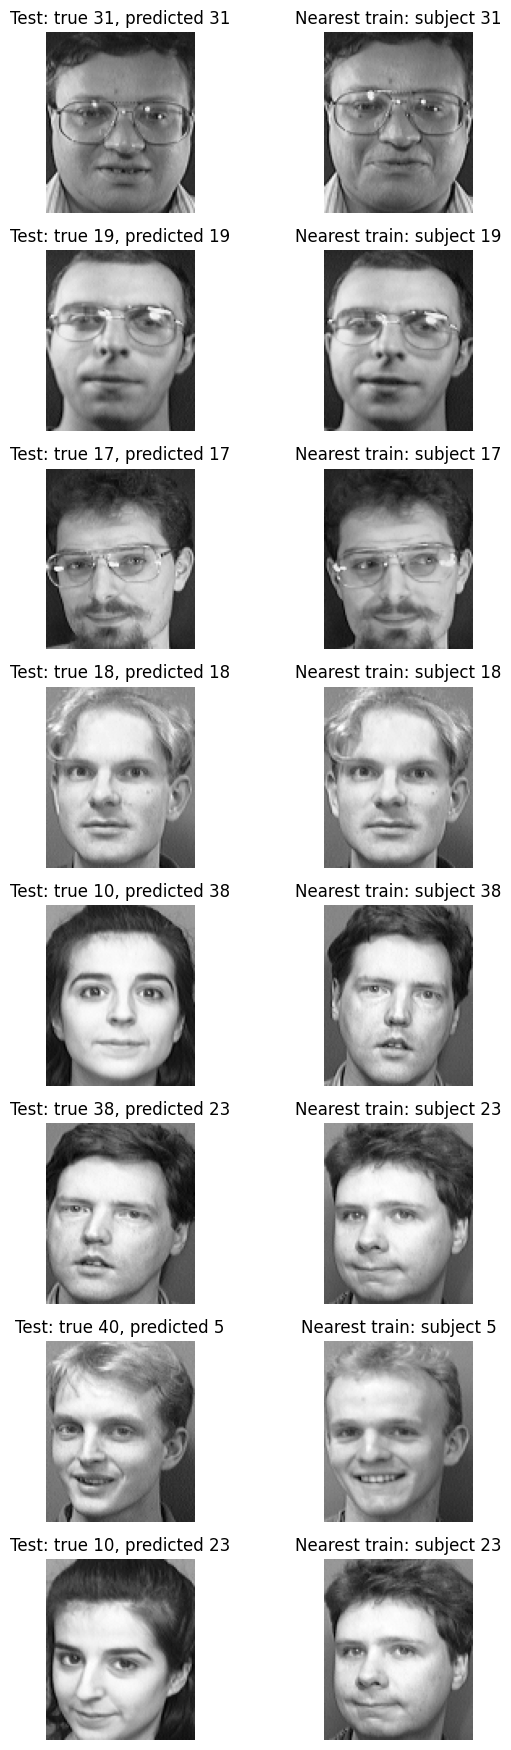

In [8]:
def nearest_face(train_features, train_labels, test_features):
    distances = np.sqrt(((test_features[:, None, :] - train_features[None, :, :]) ** 2).sum(axis=2))
    nearest_indices = np.argmin(distances, axis=1)
    return train_labels[nearest_indices], nearest_indices, distances[np.arange(len(test_features)), nearest_indices]

raw_predictions, raw_nearest_indices, raw_distances = nearest_face(X_train, y_train, X_test)
pca_predictions, pca_nearest_indices, pca_distances = nearest_face(Z_train, y_train, Z_test)

raw_accuracy = accuracy_score(y_test, raw_predictions)
pca_accuracy = accuracy_score(y_test, pca_predictions)
print(f"Raw-pixel nearest-neighbor accuracy: {raw_accuracy:.4f}")
print(f"PCA nearest-neighbor accuracy ({k90} components): {pca_accuracy:.4f}")

correct = [i for i in range(len(y_test)) if pca_predictions[i] == y_test[i]][:4]
incorrect = [i for i in range(len(y_test)) if pca_predictions[i] != y_test[i]][:4]
selected = correct + incorrect
if selected:
    fig, axes = plt.subplots(len(selected), 2, figsize=(7, 2.2*len(selected)), squeeze=False)
    for row, i in enumerate(selected):
        axes[row, 0].imshow(X_test[i].reshape(height, width), cmap="gray")
        axes[row, 0].set_title(f"Test: true {y_test[i]}, predicted {pca_predictions[i]}")
        axes[row, 0].axis("off")
        match_i = pca_nearest_indices[i]
        axes[row, 1].imshow(X_train[match_i].reshape(height, width), cmap="gray")
        axes[row, 1].set_title(f"Nearest train: subject {y_train[match_i]}")
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_PATH / "recognition_matches.png", dpi=160)
    plt.show()


,Model,Components,Accuracy
0,SVM (RBF),91,0.9833
1,Logistic Regression,91,0.9750
2,Nearest Neighbor (PCA),91,0.9667
3,Nearest Neighbor (raw pixels),91,0.9667
4,KNN (k=1),91,0.9667
5,"KNN (k=3, distance weights)",91,0.9417


Best model in this comparison: SVM (RBF)
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         3
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         3
           8       0.75      1.00      0.86         3
           9       1.00      1.00      1.00         3
          10       1.00      0.67      0.80         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         3
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         3
          16       1.00      1.00      1.00         3
          17       1.00      1.00      1

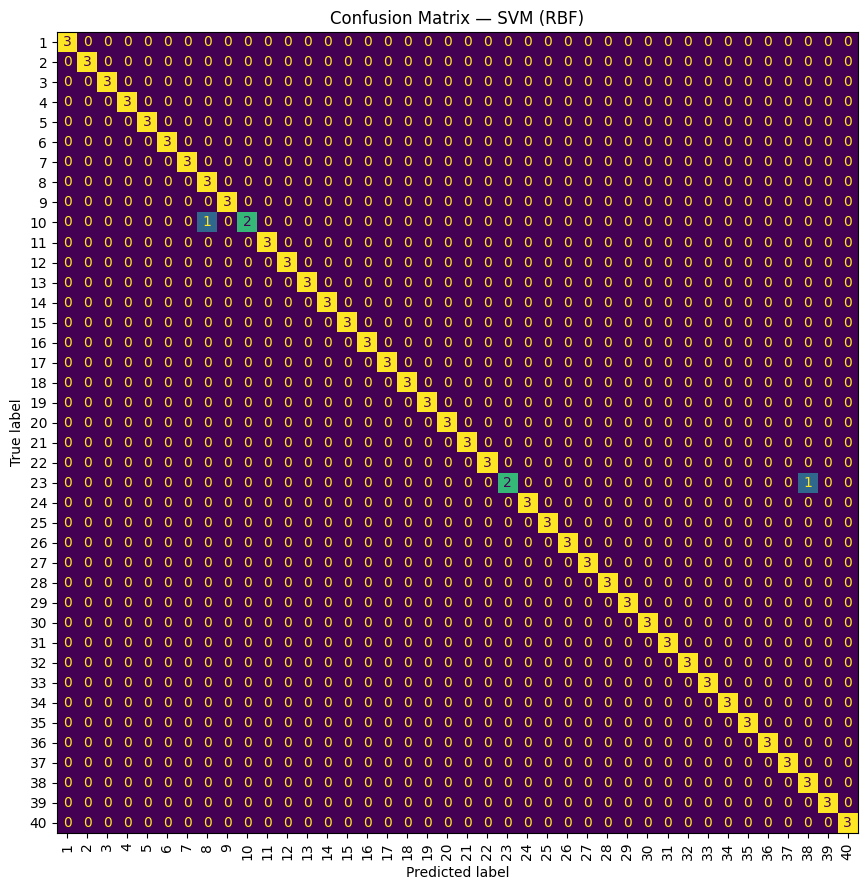

In [9]:
models = {
    "Nearest Neighbor (raw pixels)": None,
    "Nearest Neighbor (PCA)": None,
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
    "KNN (k=3, distance weights)": KNeighborsClassifier(n_neighbors=3, weights="distance"),
    "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0, random_state=42),
    "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale"),
}

predictions = {
    "Nearest Neighbor (raw pixels)": raw_predictions,
    "Nearest Neighbor (PCA)": pca_predictions,
}
comparison_rows = []
for name, model in models.items():
    if model is None:
        pred = predictions[name]
    else:
        model.fit(Z_train, y_train)
        pred = model.predict(Z_test)
        predictions[name] = pred
    comparison_rows.append({"Model": name, "Components": k90,
                            "Accuracy": accuracy_score(y_test, pred)})

comparison = pd.DataFrame(comparison_rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(comparison.style.format({"Accuracy": "{:.4f}"}))
comparison.to_csv(OUTPUT_PATH / "ml_comparison.csv", index=False)

best_name = comparison.iloc[0]["Model"]
best_predictions = predictions[best_name]
print(f"Best model in this comparison: {best_name}")
print(classification_report(y_test, best_predictions, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, ax=ax, xticks_rotation="vertical",
                                        colorbar=False)
ax.set_title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "confusion_matrix.png", dpi=160)
plt.show()


In [10]:
component_counts = sorted(set(k for k in [10, 20, 40, 60, 80, 100, k90]
                             if 1 <= k <= components_eig.shape[1]))
tuning_rows = []

for k in component_counts:
    basis = components_eig[:, :k]
    z_train_k = (X_train - mean_face) @ basis
    z_test_k = (X_test - mean_face) @ basis
    tuning_models = {
        "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
        "KNN (k=3, distance weights)": KNeighborsClassifier(n_neighbors=3, weights="distance"),
        "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0, random_state=42),
        "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale"),
    }
    for name, model in tuning_models.items():
        model.fit(z_train_k, y_train)
        score = accuracy_score(y_test, model.predict(z_test_k))
        tuning_rows.append({"Components": k, "Model": name, "Accuracy": score})

tuning = pd.DataFrame(tuning_rows).sort_values(["Model", "Components"])
display(tuning.pivot(index="Components", columns="Model", values="Accuracy").style.format("{:.4f}"))
tuning.to_csv(OUTPUT_PATH / "component_tuning.csv", index=False)

summary = pd.DataFrame([
    ["Images", n_images],
    ["Subjects", len(np.unique(y))],
    ["Image dimensions", f"{height} x {width}"],
    ["Training images", len(X_train)],
    ["Test images", len(X_test)],
    ["Components for >=90% variance", k90],
    ["Variance retained (%)", round(cumulative_variance[k90-1]*100, 2)],
    ["Reconstruction MSE", round(float(reconstruction_mse), 3)],
    ["Raw-pixel nearest-neighbor accuracy", round(float(raw_accuracy), 4)],
    ["PCA nearest-neighbor accuracy", round(float(pca_accuracy), 4)],
    ["Storage ratio (original/PCA)", round(float(original_bytes/pca_bytes), 2)],
], columns=["Metric", "Value"])
display(summary)
summary.to_csv(OUTPUT_PATH / "run_summary.csv", index=False)
print(f"Figures and result files saved to: {OUTPUT_PATH.resolve()}")


Model,KNN (k=1),"KNN (k=3, distance weights)",Logistic Regression,SVM (RBF)
Components,,,,
10,0.9667,0.9083,0.8500,0.9917
20,0.9750,0.9417,0.9750,0.9750
40,0.9667,0.9417,0.9917,0.9833
60,0.9750,0.9500,0.9833,0.9750
80,0.9750,0.9417,0.9750,0.9833
91,0.9667,0.9417,0.9750,0.9833
100,0.9667,0.9500,0.9750,0.9750


,Metric,Value
0,Images,400
1,Subjects,40
2,Image dimensions,112 x 92
3,Training images,280
4,Test images,120
5,Components for >=90% variance,91
6,Variance retained (%),90.05
7,Reconstruction MSE,343.044
8,Raw-pixel nearest-neighbor accuracy,0.9667
9,PCA nearest-neighbor accuracy,0.9667


Figures and result files saved to: C:\Users\DELL\Downloads\outputs
